# PSMD 原理与实操

> **用途**：理解并亲手计算 PSMD（Peak width of Skeletonized Mean Diffusivity，骨架化平均弥散度峰宽）——脑小血管病白质损伤的 DTI 标志物。
>
> **前置条件**：已安装 FSL 6.0+（含许可证）并设置 `FSLDIR`；已安装 `dc`；已创建 conda 环境 `psmd-tool`（`conda env create -f environment.yml`）。详见 `docs/install.md`。
>
> **预计时长**：15–30 分钟（含两次 TBSS 运行，各约 5 分钟，取决于机器）。
>
> **延伸阅读**（正文末尾有完整列表）：Zanon Zotin et al., *Radiology* 2023（综述）；Baykara et al., *Ann Neurol* 2016（原始方法）。
>
> ⚠️ PSMD 非医疗设备，仅供科研使用。

## 一、PSMD 是什么

**PSMD = 骨架内 MD 直方图的 95 百分位 − 5 百分位**。

PSMD 反映主要白质纤维束上 MD 值的**异质性**：脑小血管病（SVD）造成白质微结构损伤不均匀，MD 方差增大，直方图变宽——峰宽（P95−P5）随之升高。相比逐体素分析，它全自动、计算快（单受试者数分钟）、对扫描方案鲁棒。

流程三步（对应下图 A→D 面板）：
1. **预处理**：运动/涡流校正 → 脑提取 → 张量拟合（得 FA、MD 图）
2. **骨架化**：FA 图配准到 FMRIB 1mm FA 模板，投射到模板白质骨架（FA>0.2）；同一变换用于 MD
3. **掩膜 + 直方图**：官方定制掩膜剔除伪影区后，骨架内 MD 值取 P95−P5

![图 1 ｜ PSMD 流程概览](figures/Figure-1-PSMD-pipeline-overview.jpg)

▲ **图 1 ｜ PSMD 流程概览。** 来源：Zanon Zotin MC, et al. Radiology 2023;306(3):e212780, Figure 1（DOI: 10.1148/radiol.212780）（© RSNA, 2023）。

## 二、本仓库的实现：`src/psmd.sh`

引擎为上游 PSMD pipeline **v1.9.1**（ISD Munich / MIAC，BSD-3），核心计算逻辑与已发表研究严格一致。三种输入入口：

| 入口 | 参数 | 适用 |
|------|------|------|
| 原始 DWI | `-d DWI -b bvals -r bvecs` | 未做任何校正（引擎内跑 `eddy_correct`） |
| 预处理 DWI | `-p DWI -b bvals -r bvecs` | 已做形变/运动/涡流校正（**推荐**） |
| 已拟合 FA+MD | `-f FA -m MD` | 已有 DTI 派生图（本 notebook 用此入口跑示例数据） |

常用选项：`-s` 骨架掩膜（必选）、`-o` 改算 MSMD（骨架 MD 均值）、`-g` 分半球、`-e <b>` 增强 CSF 掩膜（需 DWI 与 FSL≥6.0）、`-l` 病灶掩膜剔除、`-q` 静默（仅输出数值）、`-t` 保留临时目录（供本 notebook 绘图）。

⚠️ **与继任者 DELTA-SVD 数值不可比**：上游已有新工具 delta-svd.com，但其数值与本工具**不能混用**于同一分析。本仓库锁定 1.9.1 数值口径。

In [1]:
# 环境自检：FSL 与 dc 必须在位
!echo "FSLDIR=$FSLDIR"
!command -v fslstats tbss_1_preproc dc && echo "依赖 OK" 

FSLDIR=/home/mri/opt/fsl


/home/mri/opt/fsl/share/fsl/bin/fslstats
/home/mri/opt/fsl/share/fsl/bin/tbss_1_preproc
/usr/bin/dc
依赖 OK


## 三、实操：跑两个示例受试者

示例数据在 `examples/`（FA+MD 已拟合配对，走 `-f -m` 入口）。先跑 subjectA——**这一步约 5 分钟**，`-t` 保留 `psmdtemp` 供稍后绘图，`-q` 让输出只有最终数值：


In [2]:
!../src/psmd.sh -f ../examples/subjectA/subjectA_FA.nii.gz \
                -m ../examples/subjectA/subjectA_MD.nii.gz \
                -s ../src/skeleton_mask_2019.nii.gz -t -q

0.000263567


In [3]:
# 读取 subjectA 的骨架化 MD（psmd.sh 在 psmdtemp/tbss/ 下生成）
import nibabel as nib
import numpy as np

md_a = nib.load('psmdtemp/tbss/MD_skeletonized_masked.nii.gz').get_fdata()
print(f'subjectA 骨架体素数（非零）: {(md_a > 0).sum()}')

subjectA 骨架体素数（非零）: 85196


再跑 subjectB。**加 `-c`**：清掉上一步残留的 `psmdtemp`（否则脚本会拒绝运行——这是引擎的保护机制，`-t` 与 `-c` 可同用：先清后跑再留）：


In [4]:
!../src/psmd.sh -f ../examples/subjectB/subjectB_FA.nii.gz \
                -m ../examples/subjectB/subjectB_MD.nii.gz \
                -s ../src/skeleton_mask_2019.nii.gz -c -t -q

0.000891553


In [5]:
md_b = nib.load('psmdtemp/tbss/MD_skeletonized_masked.nii.gz').get_fdata()
print(f'subjectB 骨架体素数（非零）: {(md_b > 0).sum()}')

subjectB 骨架体素数（非零）: 85090


## 四、直方图与 PSMD 数值

psmd.sh 内部把 MD 放大了 10⁶ 倍（便于整数运算），绘图时除回。横轴单位 **×10⁻³ mm²/s**（即 μm²/ms）。红线标 P5/P95，**两线间距 = PSMD**：


/tmp/ipykernel_2615322/2591193915.py:19: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2615322/2591193915.py:19: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2615322/2591193915.py:19: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2615322/2591193915.py:20: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from font(s) DejaVu Sans.
  plt.savefig(f'../outputs_demo/{label}_MD_skeleton_histogram.png', dpi=150, bbox_inches='tight')
/tmp/ipykernel_2615322/2591193915.py:20: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from font(s) DejaVu Sans.
  plt.savefig(f'../outputs_demo/{label}_MD_skeleton_histogram.png', dpi=150, bbox_inches='tight')
/tmp/ipykernel_2615322/2591193915.py:20: UserWarning: Glyph 25968 (\N{CJK UN

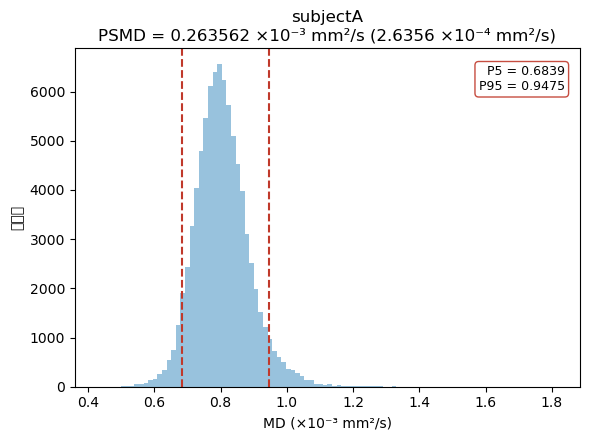

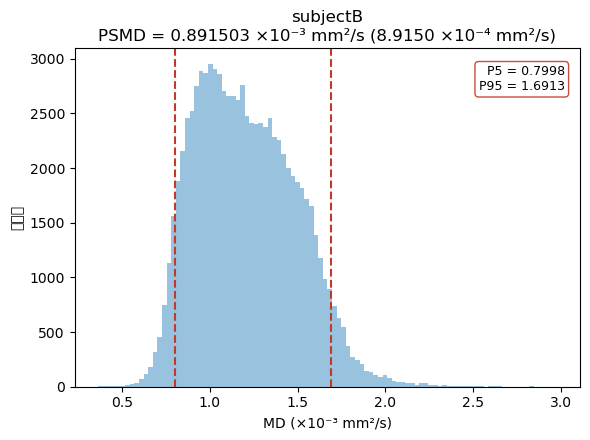

subjectA: P5=0.683919, P95=0.947482, PSMD=0.263562 ×10⁻³ mm²/s
subjectB: P5=0.799755, P95=1.691258, PSMD=0.891503 ×10⁻³ mm²/s


In [6]:
import matplotlib.pyplot as plt

results = {}
for label, md in [('subjectA', md_a), ('subjectB', md_b)]:
    fig, ax = plt.subplots(figsize=(6, 4.5))
    vals = md[md > 0] / 1000.0            # ×10⁻³ mm²/s
    p5, p95 = np.percentile(vals, 5), np.percentile(vals, 95)
    psmd = p95 - p5
    results[label] = (p5, p95, psmd)
    ax.hist(vals, bins=100, color='#7fb3d5', edgecolor='none', alpha=0.8)
    ax.axvline(p5, color='#c0392b', ls='--', lw=1.5)
    ax.axvline(p95, color='#c0392b', ls='--', lw=1.5)
    ax.set_title(f'{label}\nPSMD = {psmd:.6f} ×10⁻³ mm²/s ({psmd*10:.4f} ×10⁻⁴ mm²/s)')
    ax.set_xlabel('MD (×10⁻³ mm²/s)')
    ax.set_ylabel('体素数')
    ax.text(0.97, 0.95, f'P5 = {p5:.4f}\nP95 = {p95:.4f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='#c0392b', alpha=0.9))
    plt.tight_layout()
    plt.savefig(f'../outputs_demo/{label}_MD_skeleton_histogram.png', dpi=150, bbox_inches='tight')
    plt.show()
for k, (p5, p95, psmd) in results.items():
    print(f'{k}: P5={p5:.6f}, P95={p95:.6f}, PSMD={psmd:.6f} ×10⁻³ mm²/s')

## 五、结果判读

两位受试者的 PSMD 均以 **×10⁻⁴ mm²/s** 量级呈现（见上图标题括号内换算）——对照文献参考区间：

| 人群 | PSMD 均值区间（×10⁻⁴ mm²/s） |
|------|------------------------------|
| 社区人群 / 健康对照 | 1.54 ± 0.14 ~ 4.29 ± 0.77 |
| 脑淀粉样血管病（CAA） | 4.38 ± 1.08 ~ 4.97 ± 1.69 |
| CADASIL（弥漫白质损伤） | 5.57 ± 1.54 ~ 5.63 ± 1.56 |

（数据来源：Zanon Zotin et al. 2023 综述汇总，DOI: 10.1148/radiol.212780）

**注意**：示例数据为演示用途，数值仅示意判读方法；真实研究中 PSMD 解读需结合人群、年龄与扫描方案，**不可单凭数值下临床结论**。

**已知偏倚与对策**：
- 运动伪影、大缺血/出血病灶 → 人为抬高 PSMD；可用 `-l <病灶掩膜>` 剔除病灶区
- CSF 部分容积效应 → 脑室旁骨架体素混入 CSF 信号；有 DWI 原始数据时可用 `-e <b值>` 增强 CSF 掩膜（需 FSL≥6.0）
- 纵向/多中心研究 → 同一研究内**锁定同一工具版本**（本仓库=1.9.1），不与 DELTA-SVD 混用

## 六、批量处理：`src/psmd_batch.sh`

真实课题往往几十上百例。批处理包装遍历受试者目录、独立 scratch 隔离运行、汇总 CSV、失败不中断：


In [7]:
!../src/psmd_batch.sh -h


psmd_batch.sh — PSMD 批处理包装 v0.1.0
包装 src/psmd.sh（PSMD v1.9.1）计算骨架化平均弥散度峰宽

用法：
  psmd_batch.sh -i <受试者根目录> -o <输出CSV> [选项]

必选：
  -i <目录>   受试者根目录，其下每个一级子目录视为一个受试者
  -o <CSV>    输出 CSV 路径（UTF-8，含表头）

可选：
  -s <掩膜>   骨架掩膜（缺省：脚本同目录的 skeleton_mask_2019.nii.gz）
  -m <指标>   psmd（缺省）或 msmd（对应引擎 -o）
  -g          分半球输出（透传引擎 -g）
  -e <b值>    增强 CSF 掩膜（透传引擎 -e；需 DWI 数据与 FSL>=6.0）
  -l <掩膜>   病灶掩膜剔除（透传引擎 -l）
  -h          本帮助

CSV 列（按调用 flag 变化）：
  默认      subject,pipeline,psmd,status,error
  -g        subject,pipeline,psmd_left,psmd_right,status,error
  -m msmd   subject,pipeline,msmd,status,error（-g 时为 msmd_left,msmd_right）
  pipeline ∈ {fitted, preprocessed}；status ∈ {ok, error}

示例：
  psmd_batch.sh -i /data/subjects -o psmd_results.csv
  psmd_batch.sh -i /data/subjects -o psmd_hemis.csv -g -m msmd



In [8]:
import pandas as pd
df = pd.read_csv('../outputs_demo/psmd_batch_examples.csv')
df

,subject,pipeline,psmd,status,error
0,subjectA,fitted,0.000264,ok,NaN
1,subjectB,fitted,0.000892,ok,NaN


## 七、延伸阅读

- Zanon Zotin MC, Yilmaz P, Sveikata L, et al. **Peak Width of Skeletonized Mean Diffusivity: A Neuroimaging Marker for White Matter Injury.** *Radiology*. 2023;306(3):e212780. [doi:10.1148/radiol.212780](https://doi.org/10.1148/radiol.212780)——方法学综述，本 notebook 图 1 出处
- Baykara E, Gesierich B, Adam R, et al. **A novel imaging marker for small vessel disease based on skeletonization of white matter tracts and diffusion histograms.** *Ann Neurol*. 2016;80(4):581-592. [doi:10.1002/ana.24758](https://doi.org/10.1002/ana.24758)——PSMD 原始方法学论文
- PSMD 官网：<http://www.psmd-marker.com>
- 继任工具 DELTA-SVD：<https://delta-svd.com>（数值与本工具不可混用）
- FSL-TBSS 官方指南：<http://fsl.fmrib.ox.ac.uk/fsl/fslwiki/TBSS>

## 清理

`-t` 留下的临时目录最后清掉（它已在 .gitignore 中，即使忘了删也不会进 git）：


In [9]:
!rm -rf psmdtemp